# Fixed gradient values

`vec_init_simple()` frees every sample except the first and last, which it fixes to 0. Nonzero end values
connect the waveform to its neighbours, and `setvec_set_vals` fixes any samples you choose.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import gropt

## Nonzero end values

A flow encode (M0 = 0, M1 = 14 mT·ms²/m) that starts at −10 mT/m and ends at 20 mT/m, for example
to run straight into a readout plateau.

SolveResult(converged=True, n_iter=118, n_feval=1288, X.size=120)


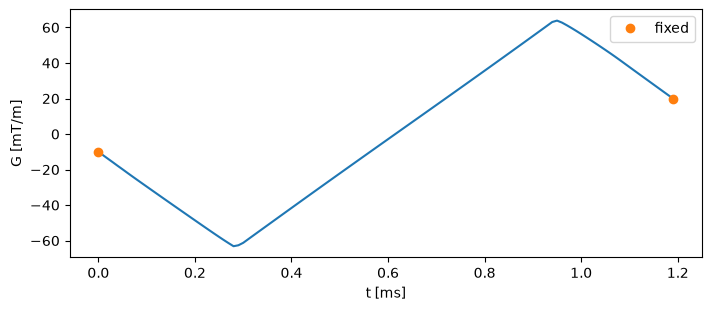

In [2]:
gp = gropt.GroptParams()
gp.dt = 10e-6
gp.N = 120
gp.vec_init_simple(first_val=-0.01, last_val=0.02)

gp.add_gmax(0.08)
gp.add_smax(200)
gp.add_moment(0, 0.0, project=True)
gp.add_moment(1, 14.0, project=True)

r = gropt.solve(gp)
print(r)

g = r.X
t_ms = np.arange(g.size) * gp.dt * 1e3
plt.figure(figsize=(7, 3), layout='constrained')
plt.plot(t_ms, g * 1e3)
plt.plot(t_ms[[0, -1]], g[[0, -1]] * 1e3, 'o', label='fixed')
plt.xlabel('t [ms]')
plt.ylabel('G [mT/m]')
plt.legend()
plt.show()

## Fixed samples inside the waveform

`setvec_set_vals` takes a vector with the value of each fixed sample and NaN for each free one. Here a
slice-select plateau (10 mT/m for 0.6 ms) is fixed, and the solver designs its ramps and the refocusing
lobe. The slice is refocused when M0 from the centre of the plateau to the end is 0: `start_idx` sets
where the moment sum starts, and `ref_idx` the sample taken as t = 0 (it matters for M1 and up).

Leave free samples for the ramps: the slew between two fixed samples is not something the solver can
change, so it is not checked.

flow_comp=False  converged=True  iterations=19
flow_comp=True   converged=True  iterations=55


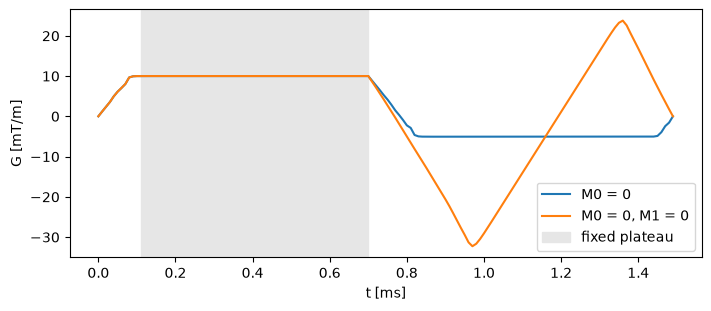

In [3]:
def slice_select(flow_comp):
    gp = gropt.GroptParams()
    gp.dt = 10e-6
    gp.N = 150
    gp.vec_init_simple()

    set_vals = gp.getvec_set_vals()   # NaN = free; vec_init_simple fixed the end points to 0
    set_vals[11:71] = 0.01            # plateau, with 10 free samples for the ramp up
    gp.setvec_set_vals(set_vals)

    c = 41                            # plateau centre
    gp.add_gmax(0.08)
    gp.add_smax(200)
    gp.add_moment(0, 0.0, start_idx=c, ref_idx=c, project=True)
    if flow_comp:
        gp.add_moment(1, 0.0, start_idx=c, ref_idx=c, project=True)
    return gp


plt.figure(figsize=(7, 3), layout='constrained')
for flow_comp in (False, True):
    gp = slice_select(flow_comp)
    r = gropt.solve(gp)
    print(f'flow_comp={flow_comp!s:5}  converged={r.converged}  iterations={r.n_iter}')
    t_ms = np.arange(gp.N) * gp.dt * 1e3
    plt.plot(t_ms, r.X * 1e3, label='M0 = 0' + (', M1 = 0' if flow_comp else ''))
plt.axvspan(0.11, 0.70, color='0.9', label='fixed plateau')
plt.xlabel('t [ms]')
plt.ylabel('G [mT/m]')
plt.legend()
plt.show()